In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

In [2]:
data_path = Path("../data")
train_path = data_path / "train.csv"
df = pd.read_csv(train_path)
print("Shape: ", df.shape)
df.head()

Shape:  (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column  Non-Null Count   Dtype
---  ------  --------------   -----
 0   date    913000 non-null  str  
 1   store   913000 non-null  int64
 2   item    913000 non-null  int64
 3   sales   913000 non-null  int64
dtypes: int64(3), str(1)
memory usage: 27.9 MB


In [4]:
df.isnull().sum()

date     0
store    0
item     0
sales    0
dtype: int64

In [5]:
df["date"] = pd.to_datetime(df["date"])

print(df["date"].min())
print(df["date"].max())

2013-01-01 00:00:00
2017-12-31 00:00:00


In [6]:
print("Number of stores:", df["store"].nunique())
print("Number of items:", df["item"].nunique())
print("Total records:", len(df))

Number of stores: 10
Number of items: 50
Total records: 913000


In [7]:
df["sales"].describe()

count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

In [8]:
sample = df[
    (df["store"] == 1) &
    (df["item"] == 1)
].copy()

print("Rows:", len(sample))
sample.head()

Rows: 1826


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


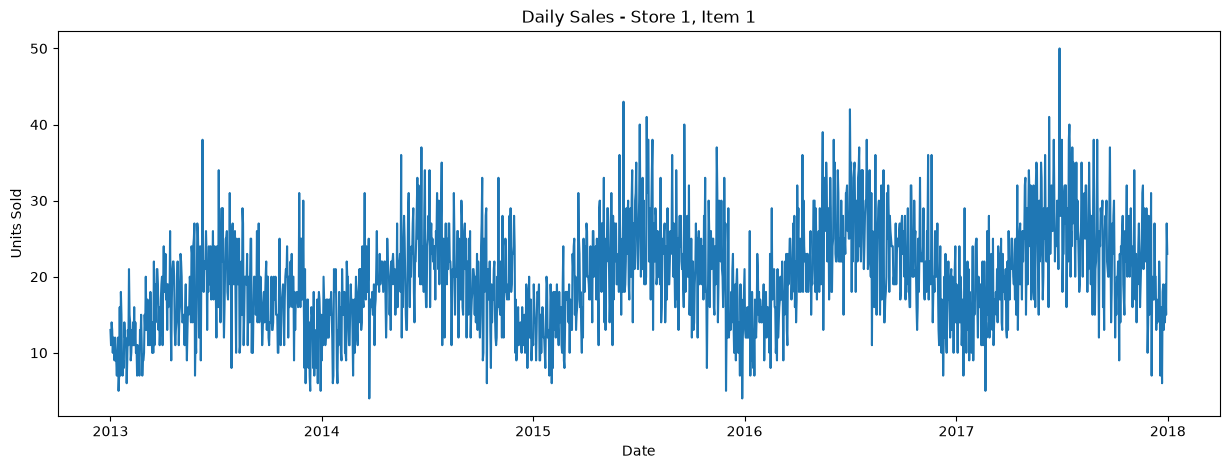

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    sample["date"],
    sample["sales"]
)

plt.title("Daily Sales - Store 1, Item 1")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.show()

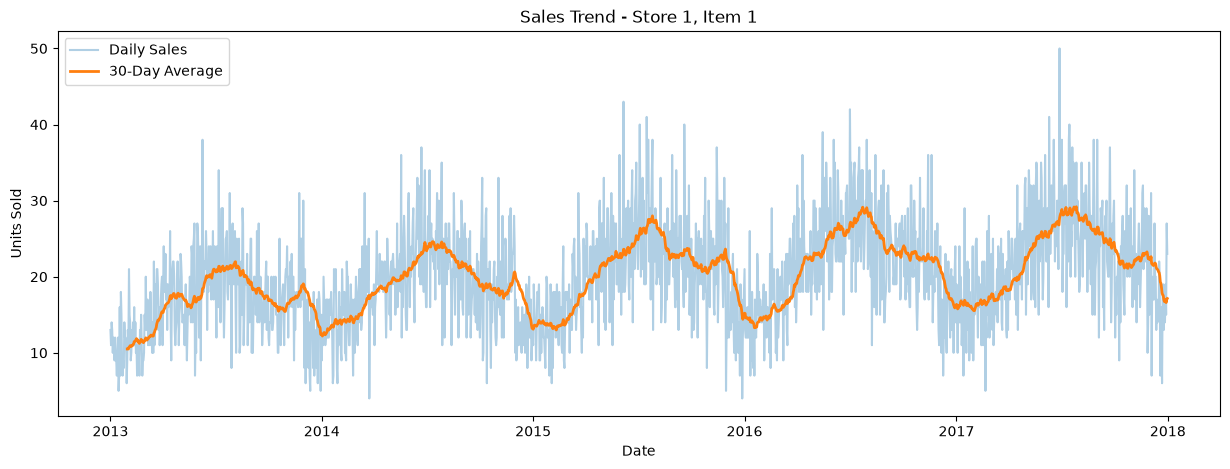

In [10]:
sample["sales_30d_avg"] = (
    sample["sales"]
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(
    sample["date"],
    sample["sales"],
    alpha=0.35,
    label="Daily Sales"
)

plt.plot(
    sample["date"],
    sample["sales_30d_avg"],
    linewidth=2,
    label="30-Day Average"
)

plt.title("Sales Trend - Store 1, Item 1")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()

plt.show()

In [11]:
sample["month"] = sample["date"].dt.month

monthly_sales = (
    sample
    .groupby("month")["sales"]
    .mean()
)

monthly_sales

month
1     13.709677
2     14.631206
3     17.600000
4     20.786667
5     22.245161
6     24.833333
7     25.967742
8     22.529032
9     21.386667
10    19.645161
11    21.366667
12    14.748387
Name: sales, dtype: float64

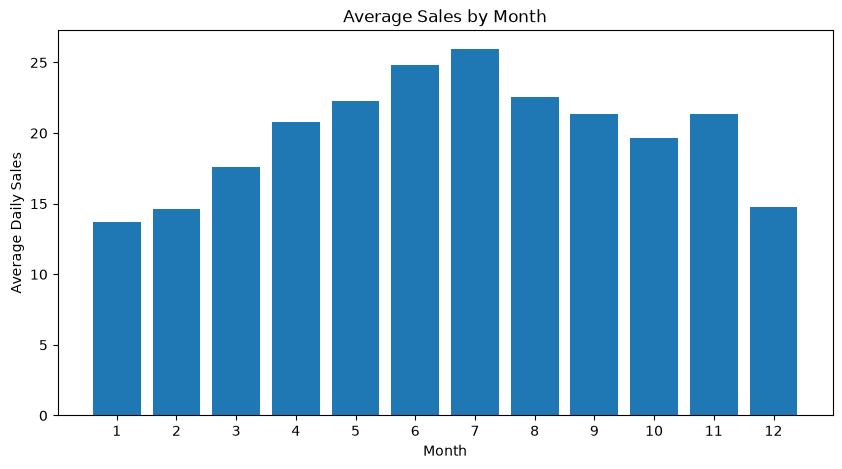

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_sales.index,
    monthly_sales.values
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")

plt.xticks(range(1, 13))

plt.show()

In [13]:
sample["day_of_week"] = sample["date"].dt.day_name()

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_sales = (
    sample
    .groupby("day_of_week")["sales"]
    .mean()
    .reindex(day_order)
)

weekly_sales

day_of_week
Monday       15.584615
Tuesday      18.168582
Wednesday    18.793103
Thursday     19.452107
Friday       21.015326
Saturday     22.973180
Sunday       23.796935
Name: sales, dtype: float64

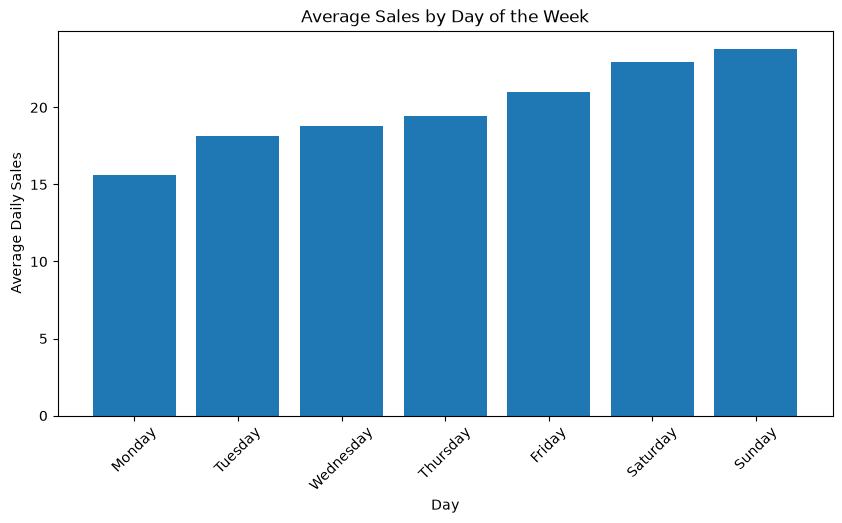

In [14]:
plt.figure(figsize=(10,5))
plt.bar(
    weekly_sales.index,
    weekly_sales.values
)

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Daily Sales")

plt.xticks(rotation=45)
plt.show()

In [15]:
df_features = df.copy()

df_features["year"] = df_features["date"].dt.year
df_features["month"] = df_features["date"].dt.month
df_features["day"] = df_features["date"].dt.day

df_features["day_of_week"] = df_features["date"].dt.dayofweek
df_features["day_of_year"] = df_features["date"].dt.dayofyear

df_features["week_of_year"] = (
df_features["date"].dt.isocalendar().week.astype(int)
)

df_features["is_weekend"] = (
    df_features["day_of_week"] >= 5
).astype(int)

df_features.head()

C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\3847351910.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df_features["day_of_week"] = df_features["date"].dt.dayofweek
C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\3847351910.py:8: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_features["day_of_year"] = df_features["date"].dt.dayofyear


,date,store,item,sales,year,month,day,day_of_week,day_of_year,week_of_year,is_weekend
0,2013-01-01,1,1,13,2013,1,1,1,1,1,0
1,2013-01-02,1,1,11,2013,1,2,2,2,1,0
2,2013-01-03,1,1,14,2013,1,3,3,3,1,0
3,2013-01-04,1,1,13,2013,1,4,4,4,1,0
4,2013-01-05,1,1,10,2013,1,5,5,5,1,1


In [16]:
print(df_features.columns.tolist())

['date', 'store', 'item', 'sales', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'is_weekend']


In [17]:
df_features = df_features.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

In [18]:
df_features["lag_1"] = (
    df_features.groupby(["store", "item"])["sales"].shift(1)
)

df_features["lag_7"] = (
    df_features.groupby(["store", "item"])["sales"].shift(7)
)

df_features["lag_14"] = (
    df_features
    .groupby(["store", "item"])["sales"].shift(14)
)

df_features["lag_28"] = (
    df_features
    .groupby(["store", "item"])["sales"].shift(28)
)

In [19]:
df_features[
    (df_features["store"] == 1) &
    (df_features["item"] == 1)
][
    [
        "date",
        "sales",
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28"
    ]
].head(35)

,date,sales,lag_1,lag_7,lag_14,lag_28
0,2013-01-01,13,NaN,NaN,NaN,NaN
1,2013-01-02,11,13.0,NaN,NaN,NaN
2,2013-01-03,14,11.0,NaN,NaN,NaN
3,2013-01-04,13,14.0,NaN,NaN,NaN
4,2013-01-05,10,13.0,NaN,NaN,NaN
5,2013-01-06,12,10.0,NaN,NaN,NaN
6,2013-01-07,10,12.0,NaN,NaN,NaN
7,2013-01-08,9,10.0,13.0,NaN,NaN
8,2013-01-09,12,9.0,11.0,NaN,NaN
9,2013-01-10,9,12.0,14.0,NaN,NaN


In [20]:
df_features["rolling_mean_7"] = (
    df_features
    .groupby(["store", "item"])["sales"]
    .transform(lambda x: x.shift(1).rolling(window=7).mean())
)
df_features["rolling_mean_30"] = (
    df_features
    .groupby(["store", "item"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(window=30).mean()
    )
)

In [21]:
df_features[
    (df_features["store"] == 1) &
    (df_features["item"] == 1)
][
    [
        "date",
        "sales",
        "lag_1",
        "lag_7",
        "rolling_mean_7",
        "rolling_mean_30"
    ]
].head(40)

,date,sales,lag_1,lag_7,rolling_mean_7,rolling_mean_30
0,2013-01-01,13,NaN,NaN,NaN,NaN
1,2013-01-02,11,13.0,NaN,NaN,NaN
2,2013-01-03,14,11.0,NaN,NaN,NaN
3,2013-01-04,13,14.0,NaN,NaN,NaN
4,2013-01-05,10,13.0,NaN,NaN,NaN
5,2013-01-06,12,10.0,NaN,NaN,NaN
6,2013-01-07,10,12.0,NaN,NaN,NaN
7,2013-01-08,9,10.0,13.0,11.857143,NaN
8,2013-01-09,12,9.0,11.0,11.285714,NaN
9,2013-01-10,9,12.0,14.0,11.428571,NaN


In [22]:
feature_columns = [
    "store",
    "item",
    "year",     
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_30"
]

df_model = df_features.dropna(
    subset = feature_columns
).copy()

print("Rows before:", len(df_features))
print("Rows after:", len(df_model))

Rows before: 913000
Rows after: 898000


In [23]:
print("Start:", df_model["date"].min())
print("End:", df_model["date"].max())

Start: 2013-01-31 00:00:00
End: 2017-12-31 00:00:00


In [24]:
split_date = pd.Timestamp("2017-10-01")

train_df = df_model[
    df_model["date"] < split_date
].copy()

val_df = df_model[
    df_model["date"] >= split_date
].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

print(
    "Train:",
    train_df["date"].min(),
    "to",
    val_df["date"].max()
)

Training rows: 852000
Validation rows: 46000
Train: 2013-01-31 00:00:00 to 2017-12-31 00:00:00


In [25]:
X_train = train_df[feature_columns]
y_train = train_df["sales"]

X_val = val_df[feature_columns]
y_val = val_df["sales"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (852000, 15)
y_train: (852000,)


In [26]:
baseline_pred = val_df["lag_7"]

In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

baseline_mae = mean_absolute_error(
    y_val,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        baseline_pred
    )
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 9.076
Baseline RMSE: 12.051


In [28]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained.")

Linear Regression model trained.


In [29]:
linear_pred = linear_model.predict(X_val)

In [30]:
linear_mae = mean_absolute_error(
    y_val,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        linear_pred
    )
)

print("LinearRegression MAE:", round(linear_mae, 3))
print("LinearRegression RMSE:", round(linear_rmse, 3)   )

LinearRegression MAE: 7.088
LinearRegression RMSE: 9.311


In [31]:
print("Baseline MAE:", round(baseline_mae, 3))
print("Linear MAE:", round(linear_mae, 3))
print()

print("Baseline RMSE:", round(baseline_rmse, 3))
print("Linear RMSE:", round(linear_rmse, 3))

Baseline MAE: 9.076
Linear MAE: 7.088

Baseline RMSE: 12.051
Linear RMSE: 9.311


In [32]:
from sklearn.ensemble import HistGradientBoostingRegressor

boost_model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    random_state=42
)

boost_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting model trained.")

Gradient Boosting model trained.


In [33]:
boost_pred = boost_model.predict(X_val)

boost_mae = mean_absolute_error(
    y_val,
    boost_pred
)

boost_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        boost_pred
    )
)

print("Gradient Boosting MAE:", round(boost_mae, 3))
print("Gradient Boosting RMSE:", round(boost_rmse, 3))

Gradient Boosting MAE: 5.967
Gradient Boosting RMSE: 7.724


In [34]:
val_results = val_df.copy()

val_results["prediction"] = boost_pred

sample_val = val_results[
    (val_results["store"] == 1) &
    (val_results["item"] == 1)
]

sample_val.head()

,date,store,item,sales,year,month,day,day_of_week,day_of_year,week_of_year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_30,prediction
1734,2017-10-01,1,1,21,2017,10,1,6,274,39,1,30.0,24.0,30.0,23.0,23.428571,24.533333,27.575740
1735,2017-10-02,1,1,12,2017,10,2,0,275,40,0,21.0,14.0,22.0,12.0,23.000000,23.966667,17.297930
1736,2017-10-03,1,1,18,2017,10,3,1,276,40,0,12.0,18.0,21.0,26.0,22.714286,23.500000,20.762816
1737,2017-10-04,1,1,15,2017,10,4,2,277,40,0,18.0,27.0,20.0,24.0,22.714286,23.333333,20.897777
1738,2017-10-05,1,1,20,2017,10,5,3,278,40,0,15.0,23.0,20.0,29.0,21.000000,23.433333,21.255102


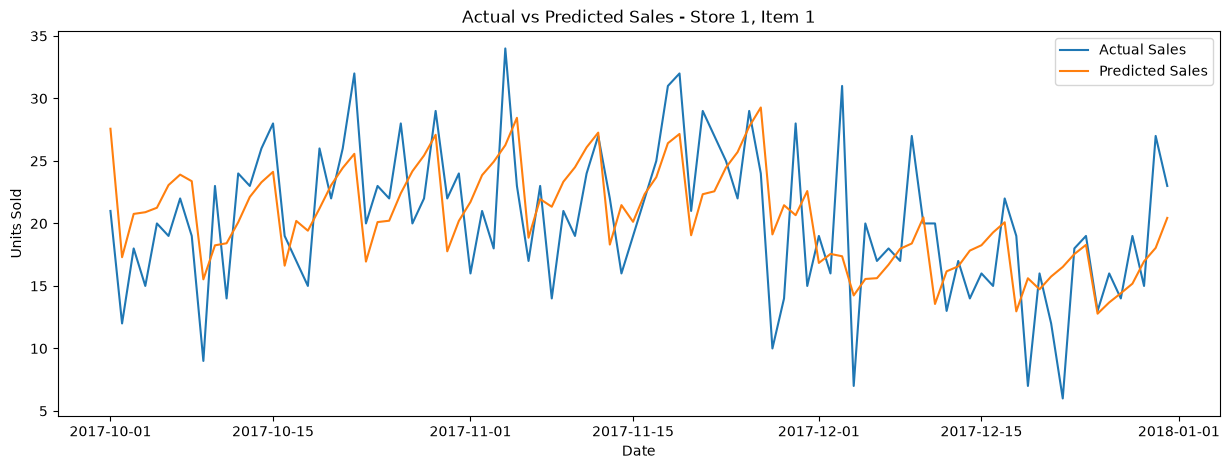

In [35]:
plt.figure(figsize=(15, 5))

plt.plot(
    sample_val["date"],
    sample_val["sales"],
    label="Actual Sales"
)

plt.plot(
    sample_val["date"],
    sample_val["prediction"],
    label="Predicted Sales"
)

plt.title(
    "Actual vs Predicted Sales - Store 1, Item 1"
)

plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()

plt.show()

In [36]:
val_results = val_df.copy()

val_results["prediction"] = boost_pred

val_results["errors"] = (
    val_results["sales"] - val_results["prediction"]
)

val_results["absolute_error"] = val_results["errors"].abs()

In [37]:
print(
    "Average error:",
    round(val_results["errors"].mean(), 3)
)

print(
    "Average absolute error:",
    round(val_results["absolute_error"].mean(),3)
)

Average error: 0.027
Average absolute error: 5.967


In [38]:
# Recreate error columns
val_results["error"] = (
    val_results["sales"]
    - val_results["prediction"]
)

val_results["absolute_error"] = (
    val_results["error"].abs()
)

# Find the 10 biggest mistakes
biggest_errors = (
    val_results
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
)

biggest_errors[
    [
        "date",
        "store",
        "item",
        "sales",
        "prediction",
        "error",
        "absolute_error"
    ]
]

,date,store,item,sales,prediction,error,absolute_error
790584,2017-10-19,9,33,117,78.922921,38.077079,38.077079
662748,2017-10-03,8,13,139,102.285202,36.714798,36.714798
226422,2017-12-30,3,24,108,71.746493,36.253507,36.253507
684693,2017-11-05,8,25,168,131.989882,36.010118,36.010118
251926,2017-10-31,3,38,62,97.825343,-35.825343,35.825343
131422,2017-11-12,2,22,113,148.142985,-35.142985,35.142985
679235,2017-11-25,8,22,165,130.162856,34.837144,34.837144
156956,2017-10-13,2,36,150,115.526163,34.473837,34.473837
757780,2017-12-22,9,15,116,81.981360,34.018640,34.018640
763255,2017-12-19,9,18,99,65.134843,33.865157,33.865157


In [39]:
# Find the 10 predictions with the largest absolute error

biggest_errors = (
    val_results
    .sort_values(
        by="absolute_error",
        ascending=False
    )
    .head(10)
    .copy()
)

print(
    biggest_errors[
        [
            "date",
            "store",
            "item",
            "sales",
            "prediction",
            "error",
            "absolute_error"
        ]
    ]
)

             date  store  item  sales  prediction      error  absolute_error
790584 2017-10-19      9    33    117   78.922921  38.077079       38.077079
662748 2017-10-03      8    13    139  102.285202  36.714798       36.714798
226422 2017-12-30      3    24    108   71.746493  36.253507       36.253507
684693 2017-11-05      8    25    168  131.989882  36.010118       36.010118
251926 2017-10-31      3    38     62   97.825343 -35.825343       35.825343
131422 2017-11-12      2    22    113  148.142985 -35.142985       35.142985
679235 2017-11-25      8    22    165  130.162856  34.837144       34.837144
156956 2017-10-13      2    36    150  115.526163  34.473837       34.473837
757780 2017-12-22      9    15    116   81.981360  34.018640       34.018640
763255 2017-12-19      9    18     99   65.134843  33.865157       33.865157


In [40]:
store_errors = (
    val_results
    .groupby("store")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
)

store_errors

store
2     6.836128
8     6.740537
3     6.381996
10    6.263758
9     6.236802
4     6.154040
1     5.674920
5     5.253756
6     5.193966
7     4.931808
Name: absolute_error, dtype: float64

In [41]:
item_errors = (
    val_results
    .groupby("item")["absolute_error"]
    .mean()
    .sort_values(ascending=False)
)

item_errors.head(10)

item
28    8.089011
13    8.087860
38    8.034612
15    7.924897
18    7.879747
25    7.809774
45    7.805833
8     7.564458
22    7.464668
36    7.441340
Name: absolute_error, dtype: float64

In [42]:
item_errors.tail(10)

item
44    4.436321
49    4.258322
16    4.110909
34    4.109628
41    4.002642
4     3.955082
47    3.835148
27    3.799157
1     3.769630
5     3.539794
Name: absolute_error, dtype: float64

In [43]:
item_variability = (
    df_model
    .groupby("item")["sales"]
    .agg(["mean", "std"])
)

item_variability["cv"] = (
    item_variability["std"] / item_variability["mean"]
)

item_variability.loc[[28,5]]

,mean,std,cv
item,,,
28,88.518541,29.276766,0.330742
5,18.497717,7.226891,0.390691


In [44]:
item_28 = df[
    (df["store"] == 1) &
    (df["item"] == 28)
].copy()

item_5 = df[
    (df["store"] == 1) &
    (df["item"] == 5)
].copy()

print("Item 28 rows:", len(item_28))
print("Item 5 rows:", len(item_5))

Item 28 rows: 1826
Item 5 rows: 1826


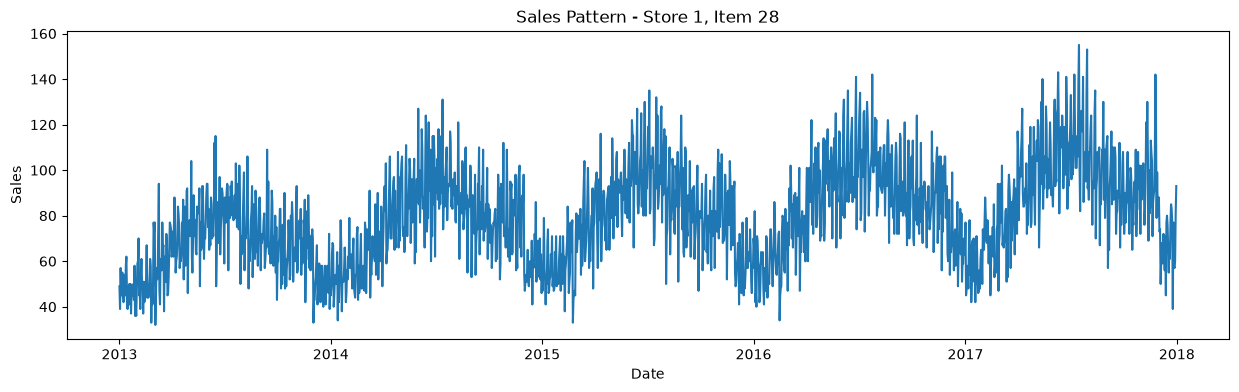

In [45]:
plt.figure(figsize=(15, 4))

plt.plot(
    item_28["date"],
    item_28["sales"],
)

plt.title("Sales Pattern - Store 1, Item 28")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()

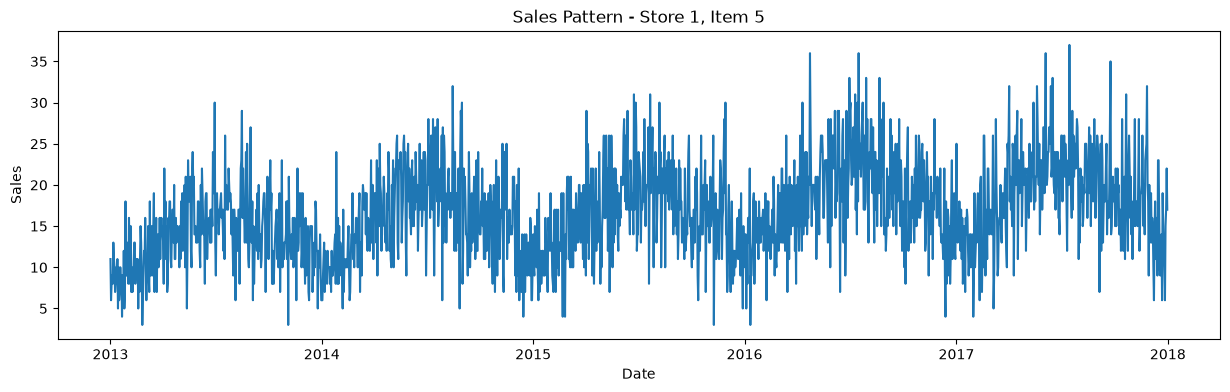

In [46]:
plt.figure(figsize=(15,4))
plt.plot(
    item_5["date"],
    item_5["sales"]
)
plt.title("Sales Pattern - Store 1, Item 5")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.show()


In [47]:
item_performance = (
    val_results
    .groupby("item")
    .agg(
        mean_sales=("sales", "mean"),
        mae=("absolute_error", "mean")
    )
)

item_performance["relative_mae"] = (
    item_performance["mae"]
    / item_performance["mean_sales"]
)

item_performance["relative_mae_percent"] = (
    item_performance["relative_mae"] * 100
)

item_performance.loc[[28, 5]]

,mean_sales,mae,relative_mae,relative_mae_percent
item,,,,
28,92.132609,8.089011,0.087797,8.779748
5,19.317391,3.539794,0.183244,18.324391


In [48]:
item_performance.sort_values(
    "relative_mae_percent",
    ascending=False
).head(10)

,mean_sales,mae,relative_mae,relative_mae_percent
item,,,,
5,19.317391,3.539794,0.183244,18.324391
41,22.789130,4.002642,0.175638,17.563819
4,22.969565,3.955082,0.172188,17.218793
47,22.969565,3.835148,0.166967,16.696651
27,22.792391,3.799157,0.166685,16.668532
1,22.940217,3.769630,0.164324,16.432409
23,30.813043,4.774054,0.154936,15.493612
16,26.600000,4.110909,0.154545,15.454546
34,27.057609,4.109628,0.151884,15.188438


In [49]:
def inventory_recommendation(
        predicted_demand,
        current_stock,
        safety_stock=10
):
    required_stock = (
        predicted_demand
        + safety_stock
    )

    reorder_quantity = max(
        0,
        required_stock - current_stock
    )

    if current_stock < predicted_demand:
        status = "Stockout Risk"

    elif current_stock < required_stock:
        status = "Low Stock"

    else:
        status = "Sufficient Stock"

    return {
        "predicted_demand": round(predicted_demand, 0),
        "current_stock": current_stock,
        "safety_stock": safety_stock,
        "required_stock": round(required_stock, 0),
        "reorder_quantity": round(reorder_quantity, 0),
        "status": status   
    }

In [50]:
example = inventory_recommendation(
    predicted_demand=40,
    current_stock=25,
    safety_stock=8
)

example

{'predicted_demand': 40,
 'current_stock': 25,
 'safety_stock': 8,
 'required_stock': 48,
 'reorder_quantity': 23,
 'status': 'Stockout Risk'}

In [51]:
example = inventory_recommendation(
    predicted_demand=40,
    current_stock=60,
    safety_stock=8
)

example

{'predicted_demand': 40,
 'current_stock': 60,
 'safety_stock': 8,
 'required_stock': 48,
 'reorder_quantity': 0,
 'status': 'Sufficient Stock'}

In [52]:
# Pick one example from the validation set
example_row = val_df.iloc[0]

# Get the matching model prediction
predicted_demand = boost_pred[0]

print("Date:", example_row["date"])
print("Store:", example_row["store"])
print("Item:", example_row["item"])
print("Actual sales:", example_row["sales"])
print("Predicted demand:", round(predicted_demand, 2))

Date: 2017-10-01 00:00:00
Store: 1
Item: 1
Actual sales: 21
Predicted demand: 27.58


In [53]:
current_stock = 20

recommendation = inventory_recommendation(
    predicted_demand=predicted_demand,
    current_stock=current_stock,
    safety_stock=8
)

recommendation

{'predicted_demand': np.float64(28.0),
 'current_stock': 20,
 'safety_stock': 8,
 'required_stock': np.float64(36.0),
 'reorder_quantity': np.float64(16.0),
 'status': 'Stockout Risk'}

In [54]:
import math
smart_safety_stock = math.ceil(
    boost_mae
)

print(
    "Smart safety stock:",
    smart_safety_stock
)

Smart safety stock: 6


In [55]:
current_stock = 20

recommendation = inventory_recommendation(
    predicted_demand=predicted_demand,
    current_stock=current_stock,
    safety_stock=smart_safety_stock
)

recommendation

{'predicted_demand': np.float64(28.0),
 'current_stock': 20,
 'safety_stock': 6,
 'required_stock': np.float64(34.0),
 'reorder_quantity': np.float64(14.0),
 'status': 'Stockout Risk'}

In [56]:
from sklearn.ensemble import HistGradientBoostingRegressor

X_all = df_model[feature_columns]
y_all = df_model["sales"]

final_model = HistGradientBoostingRegressor(
    learning_rate=0.1,
    max_iter=200,
    max_leaf_nodes=31,
    random_state=42
)

final_model.fit(
    X_all,
    y_all
)

print("Final Gradient Boosting model trained on all historical data.")

Final Gradient Boosting model trained on all historical data.


In [57]:
def forecast_next_days(
    model,
    df,
    store_id,
    item_id,
    days=7
):
    # Get historical sales for one store + item
    history = (
        df[
            (df["store"] == store_id) &
            (df["item"] == item_id)
        ]
        .sort_values("date")
        [["date", "sales"]]
        .copy()
    )

    # Convert sales history to a Python list
    sales_history = history["sales"].astype(float).tolist()

    # Last known date
    last_date = history["date"].max()

    forecasts = []

    for i in range(1, days + 1):

        future_date = last_date + pd.Timedelta(days=i)

        # ----------------------------------
        # Calendar features
        # ----------------------------------

        year = future_date.year
        month = future_date.month
        day = future_date.day

        day_of_week = future_date.dayofweek
        day_of_year = future_date.dayofyear

        week_of_year = int(
            future_date.isocalendar().week
        )

        is_weekend = int(
            day_of_week >= 5
        )


        # ----------------------------------
        # Lag features
        # ----------------------------------

        lag_1 = sales_history[-1]
        lag_7 = sales_history[-7]
        lag_14 = sales_history[-14]
        lag_28 = sales_history[-28]


        # ----------------------------------
        # Rolling averages
        # ----------------------------------

        rolling_mean_7 = np.mean(
            sales_history[-7:]
        )

        rolling_mean_30 = np.mean(
            sales_history[-30:]
        )


        # ----------------------------------
        # Create model input
        # ----------------------------------

        future_features = pd.DataFrame(
            [{
                "store": store_id,
                "item": item_id,
                "year": year,
                "month": month,
                "day": day,
                "day_of_week": day_of_week,
                "day_of_year": day_of_year,
                "week_of_year": week_of_year,
                "is_weekend": is_weekend,
                "lag_1": lag_1,
                "lag_7": lag_7,
                "lag_14": lag_14,
                "lag_28": lag_28,
                "rolling_mean_7": rolling_mean_7,
                "rolling_mean_30": rolling_mean_30
            }]
        )

        # Make sure column order matches training
        future_features = future_features[
            feature_columns
        ]


        # ----------------------------------
        # Predict
        # ----------------------------------

        prediction = model.predict(
            future_features
        )[0]

        # Sales cannot be negative
        prediction = max(
            0,
            prediction
        )


        # Save prediction
        forecasts.append({
            "date": future_date,
            "store": store_id,
            "item": item_id,
            "predicted_sales": prediction
        })


        # Add prediction to history
        # so it can help predict the next day
        sales_history.append(prediction)


    return pd.DataFrame(forecasts)

In [58]:
forecast_7d = forecast_next_days(
    model=final_model,
    df=df,
    store_id=1,
    item_id=1,
    days=7
)

forecast_7d

C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\1866079968.py:39: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = future_date.dayofweek
C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\1866079968.py:40: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = future_date.dayofyear
C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\1866079968.py:39: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  day_of_week = future_date.dayofweek
C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\1866079968.py:40: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  day_of_year = future_date.dayofyear
C:\Users\swanz\AppData\Local\Temp\ipykernel_18012\1866079968.py:39: Pand

,date,store,item,predicted_sales
0,2018-01-01,1,1,13.749706
1,2018-01-02,1,1,15.184903
2,2018-01-03,1,1,14.659574
3,2018-01-04,1,1,15.823183
4,2018-01-05,1,1,16.825791
5,2018-01-06,1,1,18.864412
6,2018-01-07,1,1,19.942136


In [63]:
def weekly_inventory_recommendation(
        forecast_df,
        current_stock,
        safety_stock
):
    total_predicted_demand = (
        forecast_df["predicted_sales"].sum()
    )

    required_stock = (
        total_predicted_demand
        + safety_stock
    )

    reorder_quantity = max(
        0,
        required_stock - current_stock
    )

    if current_stock < total_predicted_demand: 
        status = "Stockout Risk"

    elif current_stock < required_stock:
        status = "Low Stock"

    else: 
        status = "Stock Sufficient"

    return {
        "7_day_predicted_demand": round(
            total_predicted_demand
        ),
        "current_stock": current_stock,
        "safety_stock": safety_stock,
        "required_stock": round(
            required_stock
        ),
        "recommended_reorder": round(
            reorder_quantity
        ),
        "status": status
    }

In [64]:
weekly_recommendation = (
    weekly_inventory_recommendation(
        forecast_df = forecast_7d,
        current_stock=100,
        safety_stock=smart_safety_stock
    )
)

weekly_recommendation

{'7_day_predicted_demand': 115,
 'current_stock': 100,
 'safety_stock': 6,
 'required_stock': 121,
 'recommended_reorder': 21,
 'status': 'Stockout Risk'}

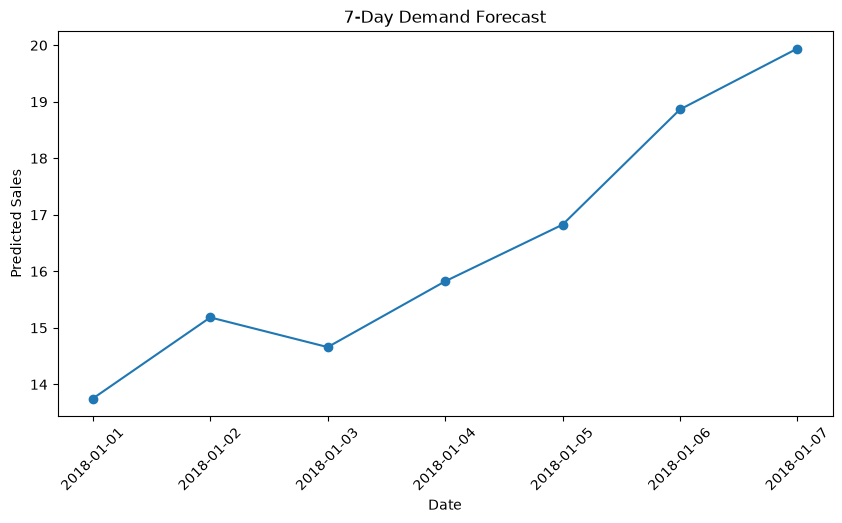

In [65]:
plt.figure(figsize=(10,5))

plt.plot(
    forecast_7d["date"],
    forecast_7d["predicted_sales"],
    marker="o"
)

plt.title("7-Day Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Sales")

plt.xticks(rotation=45)

plt.show()

In [67]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(exist_ok=True)

joblib.dump(
    final_model,
    models_dir/ "stockwise_gradient_boosting.pkl"
)

print("Final model saved successfully")

Final model saved successfully


In [68]:
joblib.dump(
    feature_columns,
    models_dir/ "feature_columns.pkl"
)

print("Feature columns saved")

Feature columns saved
